# BoT-SORT multi-object tracking with OpenVINO™

This tutorial loads the original PyTorch weights for **conversion only**, exports
FP32 OpenVINO IR, then FP16 and NNCF INT8 IR, validates the models, optionally measures
MOT17 val-half MOTA and IDF1 and runs a bundled 30-second video. Tracking stays on the
host, so tracker thresholds and per-sequence overrides are saved separately.
PyTorch is used here only to construct the models for conversion.

#### Table of contents:
- [Install dependencies](#Install-dependencies)
- [Load the model and tracker configuration](#Load-the-model-and-tracker-configuration)
- [Export FP32 and FP16 IR](#Export-FP32-and-FP16-IR)
- [Select device and validate inference](#Select-device-and-validate-inference)
- [Quantize to INT8](#Quantize-to-INT8)
- [Evaluate on MOT17 val-half](#Evaluate-on-MOT17-val-half)
- [Track the first 30 seconds](#Track-the-first-30-seconds)

See [README.md](./README.md) for the model and data protocol. The notebook
fetches the public model sources and checkpoints when absent. [botsort_nb_utils.py](./botsort_nb_utils.py)
supplies the host-side tracking used by both network precisions.

### Installation Instructions

This is a self-contained example that relies solely on its own code.

We recommend  running the notebook in a virtual environment. You only need a Jupyter server to start.
For details, please refer to [Installation Guide](https://github.com/openvinotoolkit/openvino_notebooks/blob/latest/README.md#-installation-guide).

<img referrerpolicy="no-referrer-when-downgrade" src="https://static.scarf.sh/a.png?x-pxid=5b5a4db0-7875-4bfb-bdbd-01698b5b1a77&file=notebooks/bot-sort/bot-sort.ipynb" />

## Install dependencies
[back to top ⬆️](#Table-of-contents:)

This cell installs Python dependencies in the current kernel. PyTorch runs conversion on CPU; OpenVINO can run the exported models on GPU.

In [1]:
%pip install -q --extra-index-url https://download.pytorch.org/whl/cpu "torch>=2.5" torchvision "openvino>=2026.3" opencv-python numpy scipy pandas matplotlib "motmetrics>=1.4" lap loguru thop yacs termcolor pyyaml tqdm imageio-ffmpeg requests gdown nncf ipywidgets

Note: you may need to restart the kernel to use updated packages.


## Load the model and tracker configuration
[back to top ⬆️](#Table-of-contents:)

YOLOX-X detects people and FastReID SBS-S50 embeds person crops. The tracker and camera-motion compensation remain on the host. The notebook fetches the public model source and checkpoints on first use.

In [2]:
import copy
import json
import os
import subprocess
import sys
import ipywidgets as widgets
import time
from pathlib import Path

import cv2
import numpy as np
import openvino as ov
import torch
from IPython.display import Image, Markdown, display
import botsort_nb_utils as U

sys.path.insert(0, str(U.NB_DIR.parents[1] / 'utils'))
# Read more about telemetry collection at https://github.com/openvinotoolkit/openvino_notebooks?tab=readme-ov-file#-telemetry
from notebook_utils import collect_telemetry

collect_telemetry("bot-sort.ipynb")

PROJECT = U.ROOT
if not U.REPO.is_dir():
    U.REPO.parent.mkdir(parents=True, exist_ok=True)
    subprocess.run(["git", "clone", "--depth", "1", "https://github.com/NirAharon/BoT-SORT.git", str(U.REPO)], check=True)

core = ov.Core()
OUT = PROJECT / "notebooks" / "openvino_tutorial_2026_3" if PROJECT != U.NB_DIR else U.NB_DIR / "output"
IR_DIR = OUT / "models"
(OUT / "results").mkdir(parents=True, exist_ok=True)
print("Model source:", U.REPO, "| OpenVINO devices:", core.available_devices)
for path, model_id in (
    (U.DET_WEIGHTS, U.DET_WEIGHTS_GDRIVE),
    (U.REID_WEIGHTS, U.REID_WEIGHTS_GDRIVE),
):
    if not path.is_file():
        import gdown
        path.parent.mkdir(parents=True, exist_ok=True)
        downloaded = gdown.download(id=model_id, output=str(path), quiet=False)
        if not downloaded or not path.is_file():
            raise RuntimeError(f"Could not download the official BoT-SORT checkpoint to {path}")
cfg = copy.deepcopy(U.DEFAULT_CONFIG)
detector = U.build_detector(U.DET_WEIGHTS)
reid = U.build_reid(U.REID_WEIGHTS)
SHAPES = {
    "detector": [1, 3, *cfg["detector"]["input_size_hw"]],
    "reid": [cfg["reid"]["batch"], 3, *cfg["reid"]["input_hw"]],
}
print("Network shapes:", SHAPES)
print("Tracker configuration:", json.dumps(cfg["tracker"], indent=2))

Model source: ./model/BoT-SORT_repo | OpenVINO devices: ['CPU', 'GPU', 'NPU']


Network shapes: {'detector': [1, 3, 800, 1440], 'reid': [8, 3, 384, 128]}
Tracker configuration: {
  "track_high_thresh": 0.6,
  "track_low_thresh": 0.1,
  "new_track_thresh": 0.7,
  "track_buffer": 30,
  "match_thresh": 0.8,
  "proximity_thresh": 0.5,
  "appearance_thresh": 0.25,
  "mot20": false,
  "cmc_method": "file",
  "frame_rate": 30,
  "min_box_area": 10,
  "max_aspect_ratio_w_over_h": 1.6
}


## Export FP32 and FP16 IR
[back to top ⬆️](#Table-of-contents:)

Export each network to FP32 IR, then produce FP16 IR from FP32. Save the same tracking configuration with each pair of networks.

In [3]:
NAMES = {"detector": "botsort_yolox_x_detector.xml", "reid": "botsort_sbs_s50_reid.xml"}
def ir(variant, network):
    return IR_DIR / variant / NAMES[network]

def save_ir(model, path, fp16):
    path.parent.mkdir(parents=True, exist_ok=True)
    model.set_rt_info(json.dumps(cfg), ["tracking_config"])
    ov.save_model(model, str(path), compress_to_fp16=fp16)
    (path.parent / "botsort_config.json").write_text(json.dumps(cfg, indent=2))

for network, module in (("detector", detector), ("reid", reid)):
    fp32_xml, fp16_xml = ir("FP32", network), ir("FP16", network)
    if not fp32_xml.exists():
        model = ov.convert_model(
            module, example_input=torch.zeros(SHAPES[network]),
            input=[ov.PartialShape(SHAPES[network])],
        )
        model.inputs[0].get_tensor().set_names({"images" if network == "detector" else "crops"})
        save_ir(model, fp32_xml, fp16=False)
    if not fp16_xml.exists():
        save_ir(core.read_model(fp32_xml), fp16_xml, fp16=True)
    print(network, fp32_xml, fp16_xml)

detector ./output/models/FP32/botsort_yolox_x_detector.xml ./output/models/FP16/botsort_yolox_x_detector.xml


reid ./output/models/FP32/botsort_sbs_s50_reid.xml ./output/models/FP16/botsort_sbs_s50_reid.xml


## Select device and validate inference
[back to top ⬆️](#Table-of-contents:)

Set `device` to an available OpenVINO device. FP32 GPU execution requests `f32` explicitly. Compare detector outputs with the original PyTorch module used for conversion.

In [4]:
device = widgets.Dropdown(options=core.available_devices,
                          value="GPU" if "GPU" in core.available_devices else "CPU",
                          description="Device:")
print("OpenVINO device:", device.value, "| available:", core.available_devices)
fp32_props = {"INFERENCE_PRECISION_HINT": "f32"} if device.value == "GPU" else {}
runners = {}
for precision in ("FP32", "FP16"):
    props = fp32_props if precision == "FP32" else {}
    runners[precision] = (
        U.ov_runner(core, ir(precision, "detector"), device.value, **props),
        U.ov_runner(core, ir(precision, "reid"), device.value, **props),
    )
video = Path("pedestrians_cc0_30s.mp4")
capture = cv2.VideoCapture(str(video))
ok, img = capture.read()
capture.release()
if not ok:
    raise FileNotFoundError(f"Cannot read the bundled video: {video}")
x, ratio = U.preprocess(img, cfg)
with torch.inference_mode():
    reference = detector(torch.from_numpy(x)).numpy()
boxes = U.postprocess(reference, ratio, cfg)
selected = boxes[boxes[:, 4] > 0.6]
if not len(selected):
    raise ValueError("No confident detections in the MOT17 sample for ReID verification")
crops, n_valid = next(
    U.batched(U.reid_crops(img, selected, tuple(cfg["reid"]["input_hw"])), cfg["reid"]["batch"])
)
with torch.inference_mode():
    ref_embeddings = U.normalize_feats(reid(torch.from_numpy(crops)).numpy()[:n_valid])
for precision, (det_run, _) in runners.items():
    prediction = det_run(x)
    print(precision, "detector cosine vs PyTorch FP32:", U.cosine(prediction, reference))
    embedding = U.normalize_feats(runners[precision][1](crops)[:n_valid])
    print(precision, "ReID embedding cosine:", np.mean(np.sum(embedding * ref_embeddings, axis=1)))

OpenVINO device: GPU | available: ['CPU', 'GPU', 'NPU']


FP32 detector cosine vs PyTorch FP32: 0.9999999999995398
FP32 ReID embedding cosine: 1.0
FP16 detector cosine vs PyTorch FP32: 0.9999995908071244
FP16 ReID embedding cosine: 0.99999297


## Quantize to INT8
[back to top ⬆️](#Table-of-contents:)

Calibrate **both FP32 IRs** on 32 spaced frames of the bundled clip: full frames for the detector and actual detected-person crops for FastReID. NNCF's mixed preset keeps detector box decode and ReID GeM/neck in float. This self-contained video calibration is for a runnable tutorial, **not** an independent MOTA/IDF1 measurement.

In [5]:
def calibration_frames(path, count=32):
    cap = cv2.VideoCapture(str(path))
    if not cap.isOpened():
        raise FileNotFoundError(f"Cannot open calibration video: {path}")
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    if total < count:
        cap.release()
        raise ValueError(f"Need at least {count} video frames for INT8 calibration; got {total}")
    indices = set(np.linspace(0, total - 1, count).round().astype(int))
    frames = []
    for index in range(total):
        ok, frame = cap.read()
        if not ok:
            cap.release()
            raise RuntimeError(f"Could not read calibration frame {index + 1} from {path}")
        if index in indices:
            frames.append(frame)
    cap.release()
    if len(frames) != count:
        raise RuntimeError(f"Expected {count} calibration frames, got {len(frames)}")
    return frames
import nncf

int8_paths = {network: ir("INT8", network) for network in NAMES}
if any(not path.exists() for path in int8_paths.values()):
    frames = calibration_frames(video)
    detector_inputs = []
    reid_inputs = []
    for frame in frames:
        input_frame, ratio = U.preprocess(frame, cfg)
        detector_inputs.append(input_frame)
        if not int8_paths["reid"].exists():
            boxes = U.postprocess(runners["FP32"][0](input_frame), ratio, cfg)
            person_crops = U.reid_crops(frame, boxes[boxes[:, 4] > 0.6],
                                        tuple(cfg["reid"]["input_hw"]))
            reid_inputs.extend(batch for batch, _ in U.batched(person_crops, cfg["reid"]["batch"]))
    del frames
    if not int8_paths["reid"].exists() and len(reid_inputs) < 8:
        raise RuntimeError(f"Only {len(reid_inputs)} person-crop batches for ReID calibration; need at least 8")
    for network, inputs in (("detector", detector_inputs), ("reid", reid_inputs)):
        if int8_paths[network].exists():
            continue
        model = core.read_model(ir("FP32", network))
        ops = model.get_ordered_ops()
        if network == "detector":
            last_transpose = max(i for i, op in enumerate(ops) if op.get_type_name() == "Transpose")
            ignored = [op.get_friendly_name() for op in ops[last_transpose:]
                       if op.get_type_name() not in ("Constant", "Result")]
        else:
            ignored = [op.get_friendly_name() for op in ops
                       if op.get_friendly_name().startswith("__module.heads.")
                       and op.get_type_name() not in ("Constant", "Result")]
        quantized = nncf.quantize(
            model, nncf.Dataset(inputs),
            subset_size=len(inputs), preset=nncf.QuantizationPreset.MIXED,
            ignored_scope=nncf.IgnoredScope(names=ignored, validate=False),
        )
        save_ir(quantized, int8_paths[network], fp16=False)
        del quantized
runners["INT8"] = tuple(
    U.ov_runner(core, int8_paths[network], device.value)
    for network in ("detector", "reid")
)
for network, path in int8_paths.items():
    fq_count = sum(op.get_type_name() == "FakeQuantize"
                   for op in core.read_model(path).get_ordered_ops())
    if fq_count == 0:
        raise RuntimeError(f"INT8 {network} IR has no FakeQuantize nodes: {path}")
    print(f"NNCF {nncf.__version__} | {network} INT8 IR: {path} | {fq_count} FakeQuantize nodes")
det_int8, reid_int8 = runners["INT8"]
print("INT8 detector cosine vs PyTorch FP32:", U.cosine(det_int8(x), reference))
print("INT8 ReID embedding cosine:",
      np.mean(np.sum(U.normalize_feats(reid_int8(crops)[:n_valid]) * ref_embeddings, axis=1)))

INFO:nncf:9 ignored nodes were found by names in the NNCFGraph


INFO:nncf:Not adding activation input quantizer for operation: 376 __module.model.head/aten::permute/Transpose


INFO:nncf:Not adding activation input quantizer for operation: 386 aten::slice/Slice


INFO:nncf:Not adding activation input quantizer for operation: 387 aten::slice/Slice_1


INFO:nncf:Not adding activation input quantizer for operation: 388 aten::slice/Slice_2


...

INFO:nncf:Not adding activation input quantizer for operation: 369 __module.heads.pool_layer/aten::clamp/Maximum


INFO:nncf:Not adding activation input quantizer for operation: 377 __module.heads.pool_layer/aten::pow/Power


INFO:nncf:Not adding activation input quantizer for operation: 385 __module.heads.pool_layer/aten::adaptive_avg_pool2d/AdaptiveAvgPool


INFO:nncf:Not adding activation input quantizer for operation: 393 __module.heads.pool_layer/aten::pow/Power_1


NNCF 3.4.0 | detector INT8 IR: ./output/models/INT8/botsort_yolox_x_detector.xml | 180 FakeQuantize nodes
NNCF 3.4.0 | reid INT8 IR: ./output/models/INT8/botsort_sbs_s50_reid.xml | 190 FakeQuantize nodes
INT8 detector cosine vs PyTorch FP32: 0.9992286613024135
INT8 ReID embedding cosine: 0.9640876


## Evaluate on MOT17 val-half
[back to top ⬆️](#Table-of-contents:)

Optional: place MOT17 FRCNN train sequences in `data/MOT17/train/` and set `RUN_MOT17_ACCURACY = True` for all seven val-half sequences. Use `SEQUENCES = ['MOT17-09-FRCNN']` for a shorter run.

In [6]:
RUN_MOT17_ACCURACY = False
SEQUENCES = None
if RUN_MOT17_ACCURACY:
    if not any(U.MOT17_TRAIN.glob("MOT17-*-FRCNN/img1/*.jpg")):
        raise FileNotFoundError(f"MOT17 FRCNN train sequences required in {U.MOT17_TRAIN}")
    accuracy = {}
    for precision, (det_run, reid_run) in runners.items():
        tag = f"OV_{precision}"
        accuracy[tag] = U.mot_eval(
            det_run, reid_run, cfg, tag, seqs=SEQUENCES,
            out_root=OUT / "results" / "accuracy",
        )
    display(Markdown(
        "| OpenVINO IR | MOTA | IDF1 | IDs | Detector ms/frame | ReID ms/frame |\n"
        "|---|---:|---:|---:|---:|---:|\n" +
        "\n".join(
            f"| {tag} | {m['MOTA']:.2f} | {m['IDF1']:.2f} | {m['IDs']} | "
            f"{m['detector_ms_per_frame']:.1f} | {m['reid_ms_per_frame']:.1f} |"
            for tag, m in accuracy.items()
        )
    ))
else:
    print("MOT17 accuracy not run; set RUN_MOT17_ACCURACY=True after providing the FRCNN dataset.")

MOT17 accuracy not run; set RUN_MOT17_ACCURACY=True after providing the FRCNN dataset.


## Track the first 30 seconds
[back to top ⬆️](#Table-of-contents:)

The bundled video contains 30 seconds. FP32, FP16 and INT8 each process at most `int(30 * source_fps)` frames and display contact sheets.

**OV_FP32**: 900 frames · [Open full tracked video](./output/results/video/OV_FP32_tracked.mp4)

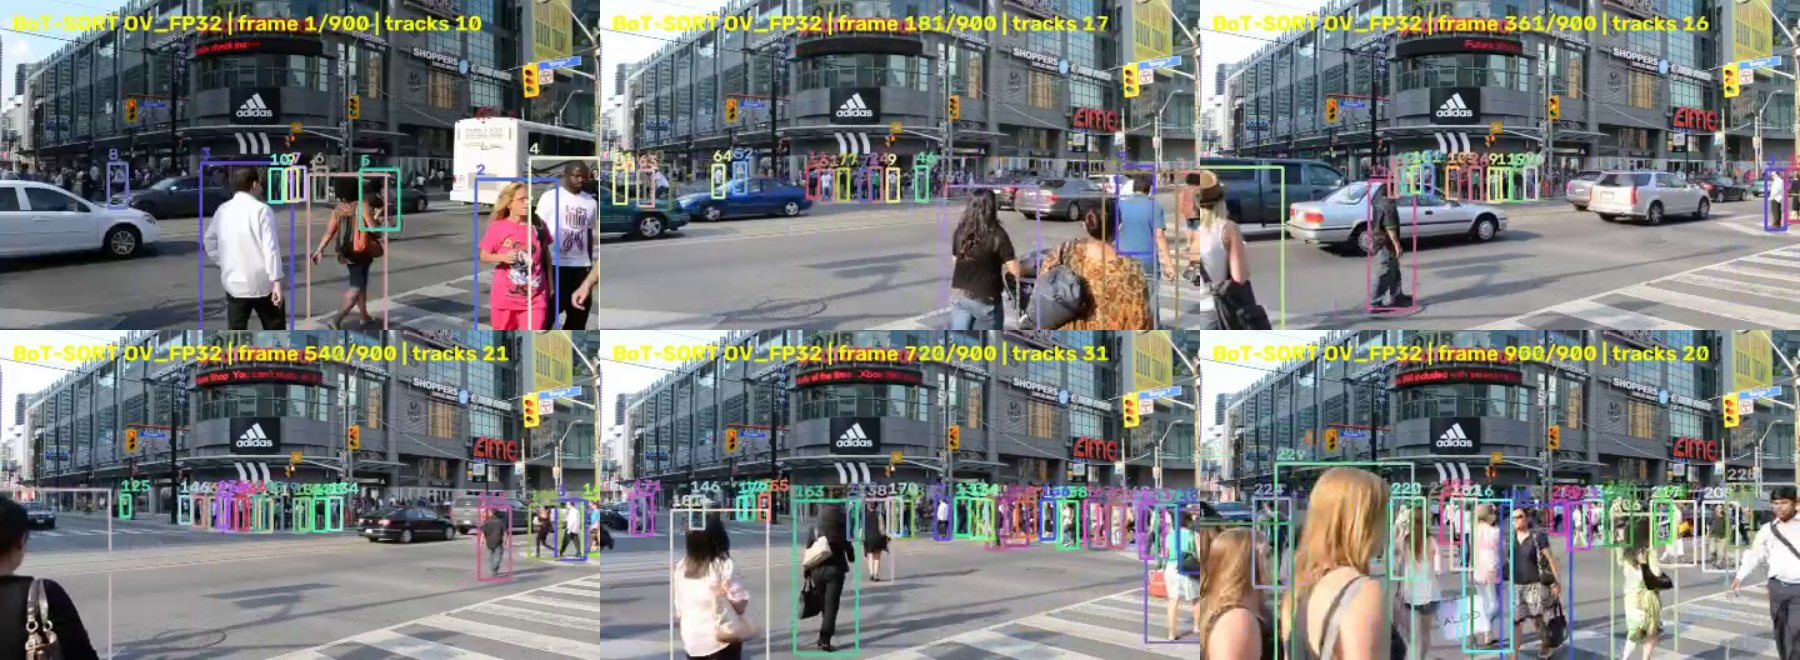

**OV_FP16**: 900 frames · [Open full tracked video](./output/results/video/OV_FP16_tracked.mp4)

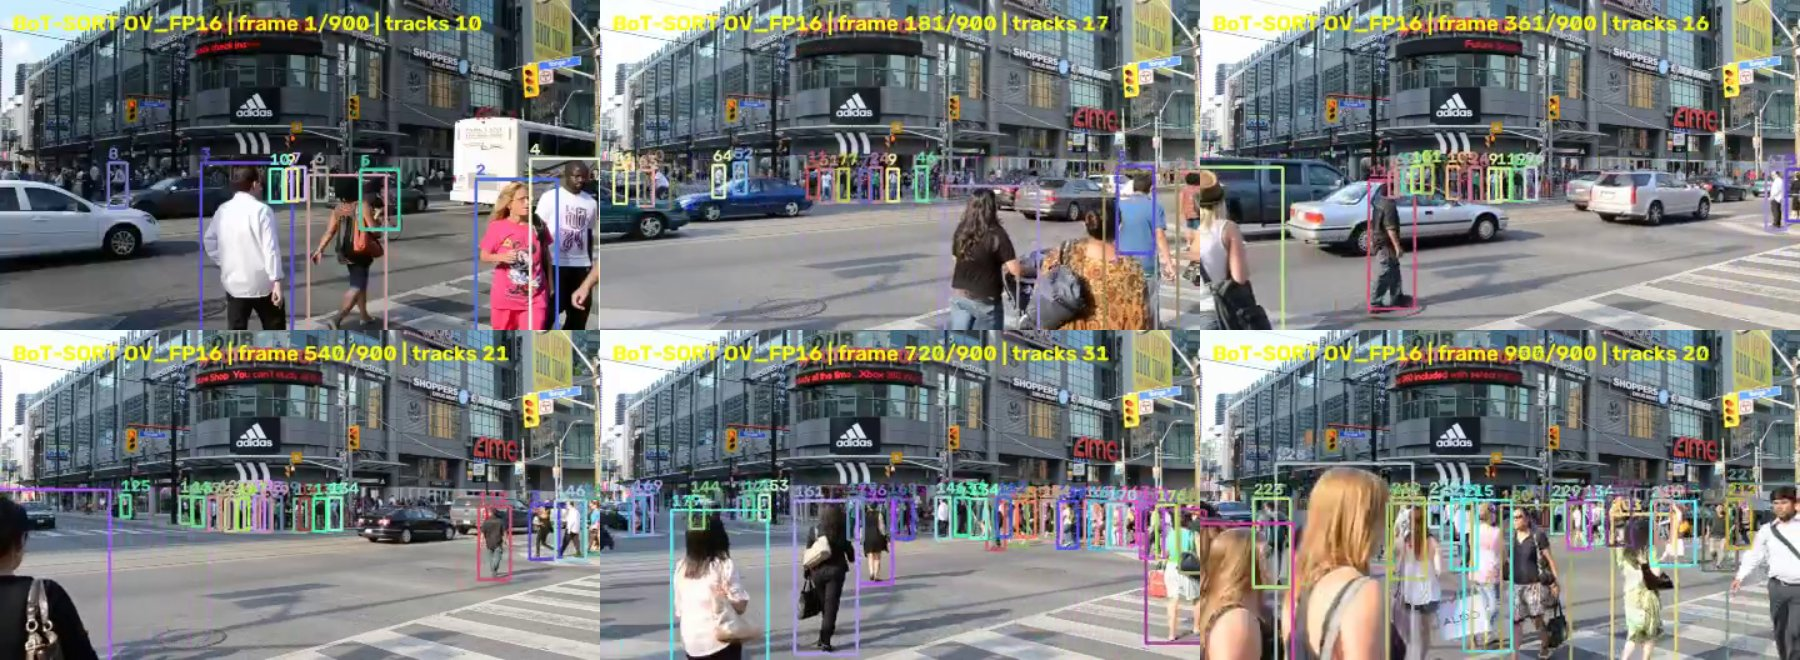

**OV_INT8**: 900 frames · [Open full tracked video](./output/results/video/OV_INT8_tracked.mp4)

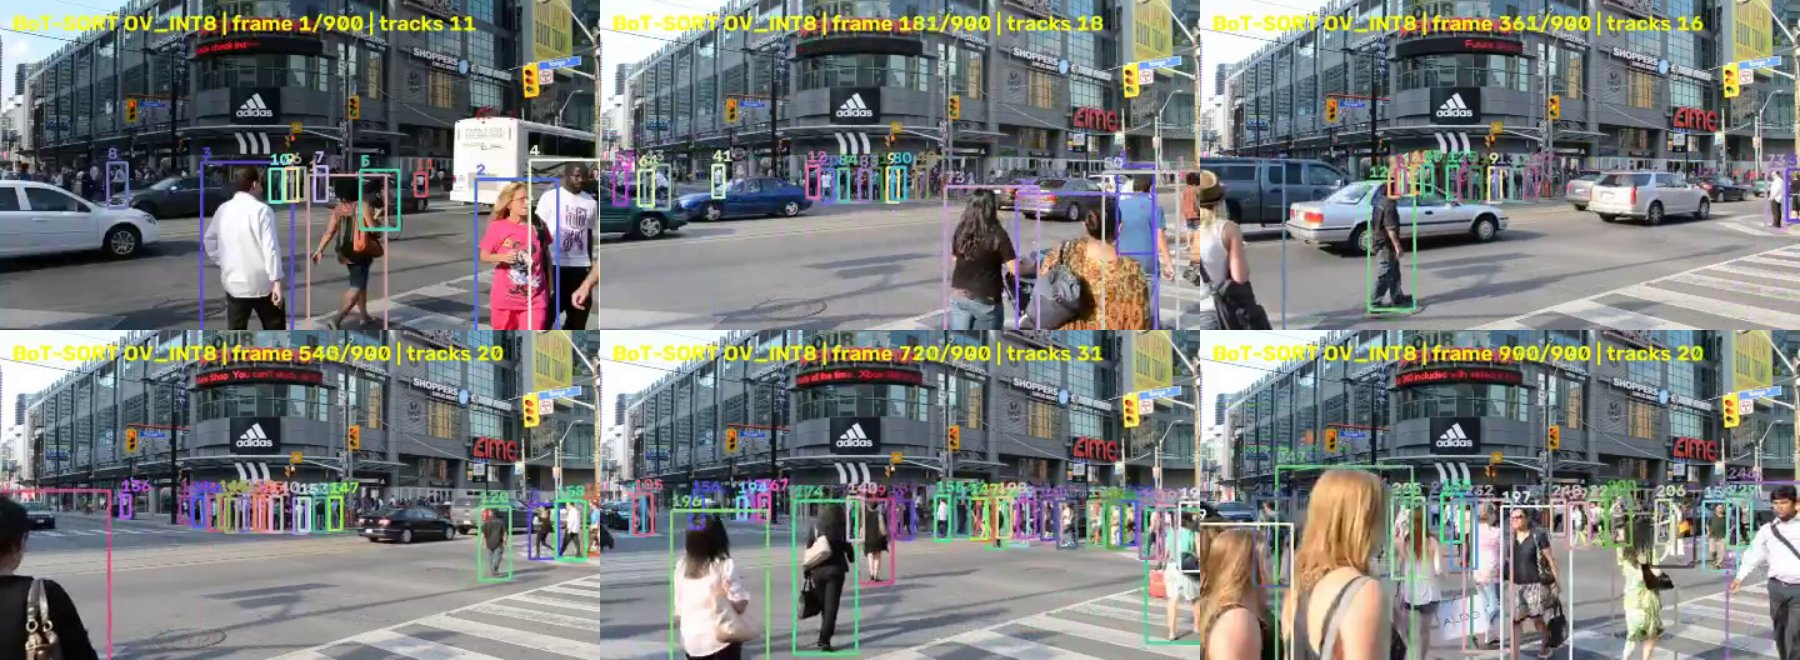

In [7]:
video = Path("pedestrians_cc0_30s.mp4")
cap = cv2.VideoCapture(str(video))
if not cap.isOpened():
    raise FileNotFoundError(f"Cannot open video: {video}")
fps = cap.get(cv2.CAP_PROP_FPS)
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
cap.release()
if fps <= 0:
    raise ValueError(f"Invalid video frame rate: {fps}")
if total_frames <= 0:
    raise ValueError(f"Cannot read video frame count: {video}")
limit = int(30 * fps)
expected_frames = min(limit, total_frames)
for precision, (det_run, reid_run) in runners.items():
    tag = f"OV_{precision}"
    result = U.track_video(
        det_run, reid_run, cfg, tag, video=video,
        out_dir=OUT / "results" / "video", max_frames=limit,
    )
    if result["stats"]["frames"] != expected_frames:
        raise RuntimeError(f"{tag} processed {result['stats']['frames']} of {expected_frames} expected frames")
    sheet = U.video_contact_sheet(
        result["stats"]["mp4"], OUT / "results" / "video" / f"{tag}_contact_sheet.jpg"
    )
    if sheet is None:
        raise RuntimeError(f"The {tag} tracked video could not be decoded for the contact sheet")
    display(Markdown(f"**{tag}**: {expected_frames} frames · "
                     f"[Open full tracked video](./{result['stats']['mp4']})"))
    display(Image(filename=sheet, width=960))

### Play the tracked videos

The MP4 players are embedded so the executed notebook still shows all three 30-second clips even when `output/` is not shared.

In [8]:
from pathlib import Path
from IPython.display import Markdown, Video, display

for tag in ("OV_FP32", "OV_FP16", "OV_INT8"):
    mp4 = Path("output/results/video") / f"{tag}_tracked.mp4"
    if not mp4.is_file():
        raise FileNotFoundError(f"Tracked video not found: {mp4}; run the tracking cell first")
    display(Markdown(f"### {tag} — 30-second tracked video"))
    display(Video(filename=str(mp4), embed=True, width=720))

### OV_FP32 — 30-second tracked video

### OV_FP16 — 30-second tracked video

### OV_INT8 — 30-second tracked video